# Feature-agnostic activation steering for an encoder–decoder model

This notebook tests whether **one shared `google/flan-t5-small` model** can be controlled by multiple activation directions during the same decoder pass.

Initial features:

- `formality`: learned from paired GYAFC informal → formal targets.
- `detoxification`: learned from paired ParaDetox toxic → neutral targets.

The design is deliberately feature-agnostic. Every feature is data plus metadata: a key, paired negative/positive targets, a selected decoder layer, a direction, and a coefficient scale. The steering engine accepts a mapping such as `{"formality": alpha, "detoxification": beta}`. A coefficient of zero is the explicit **off switch**. Adding another feature later does not require changing the hook implementation.

## Why decoder directions?

For every pair, the encoder receives the **same source message and fixed rewrite instruction**. We teacher-force two possible decoder targets: the negative side and positive side of the feature. Their paired decoder-state difference therefore measures how the output representation changes while the source context remains fixed.

In [1]:
from contextlib import ExitStack
from dataclasses import dataclass
from pathlib import Path
import json
import time

from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

from secondthought.evaluation import (
    DetoxifyToxicityScorer,
    SentenceTransformerSimilarityScorer,
    evaluate_records,
)
from secondthought.steering_rewriter import BASE_REWRITE_PROMPT, make_steering_hook

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()),
    Path.cwd(),
)
ARTIFACT_DIRECTORY = PROJECT_ROOT / "steering_experimentation" / "artifacts"
RESULT_DIRECTORY = PROJECT_ROOT / "testing" / "results"
ARTIFACT_DIRECTORY.mkdir(parents=True, exist_ok=True)
RESULT_DIRECTORY.mkdir(parents=True, exist_ok=True)

MODEL_ID = "google/flan-t5-small"
GYAFC_ROOT = Path("/Users/nandanprince/Downloads/GYAFC_Corpus")
PARADETOX_ID = "s-nlp/paradetox"
TEST_PATH = PROJECT_ROOT / "data" / "workplace_eval" / "input.jsonl"

SEED = 42
EXTRACTION_PAIRS = 8_000
HELDOUT_PAIRS = 2_000
BATCH_SIZE = 32
MAX_SOURCE_LENGTH = 192
MAX_TARGET_LENGTH = 96
ALPHAS = [0.0, 1.0, 2.0]
BETAS = [0.0, 1.0, 2.0]
INTERVENTION_SITES = ["encoder", "decoder"]

ARTIFACT_PATH = ARTIFACT_DIRECTORY / "flan_t5_small_feature_directions.pt"
LAYER_RESULTS_PATH = RESULT_DIRECTORY / "t5_feature_layer_results.csv"
PREDICTIONS_PATH = RESULT_DIRECTORY / "t5_mixed_steering_predictions.csv"
EVALUATED_PATH = RESULT_DIRECTORY / "t5_mixed_steering_evaluated.csv"
SUMMARY_PATH = RESULT_DIRECTORY / "t5_mixed_steering_summary.csv"

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID).to(device)
model.eval()
print({
    "model": MODEL_ID,
    "device": str(device),
    "encoder_layers": model.config.num_layers,
    "decoder_layers": model.config.num_decoder_layers,
    "hidden_size": model.config.d_model,
    "extraction_pairs_per_feature": EXTRACTION_PAIRS,
    "heldout_pairs_per_feature": HELDOUT_PAIRS,
})

/Users/nandanprince/Desktop/NLP_project/SecondThought/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'model': 'google/flan-t5-small', 'device': 'mps', 'encoder_layers': 8, 'decoder_layers': 8, 'hidden_size': 512, 'extraction_pairs_per_feature': 8000, 'heldout_pairs_per_feature': 2000}


## 1. Register paired feature datasets

The extraction algorithm does not know what “formality” or “detoxification” means. It only consumes the same four-column schema:

- `source`: encoder input message;
- `negative`: target on the feature’s negative side;
- `positive`: target on the feature’s positive side;
- `feature`: stable registry key.

In [2]:
@dataclass(frozen=True)
class FeatureDataset:
    key: str
    negative_label: str
    positive_label: str
    pairs: pd.DataFrame


def normalize_text(text):
    return " ".join(str(text).split()).casefold()


def prepare_pairs(frame, source_column, negative_column, positive_column, feature):
    result = frame[[source_column, negative_column, positive_column]].rename(
        columns={
            source_column: "source",
            negative_column: "negative",
            positive_column: "positive",
        }
    ).copy()
    for column in ("source", "negative", "positive"):
        result[column] = result[column].fillna("").astype(str).str.strip()
    result = result.loc[(result[["source", "negative", "positive"]] != "").all(axis=1)]
    result["negative_key"] = result["negative"].map(normalize_text)
    result["positive_key"] = result["positive"].map(normalize_text)
    result = result.loc[result["negative_key"] != result["positive_key"]]
    result = result.drop_duplicates(["negative_key", "positive_key"])
    result = result.sample(frac=1, random_state=SEED).drop_duplicates("negative_key")
    result["feature"] = feature
    return result.reset_index(drop=True)


gyafc_parts = []
for domain in ("Entertainment_Music", "Family_Relationships"):
    informal = (GYAFC_ROOT / domain / "train" / "informal").read_text().splitlines()
    formal = (GYAFC_ROOT / domain / "train" / "formal").read_text().splitlines()
    if len(informal) != len(formal):
        raise ValueError(f"Unaligned GYAFC train files for {domain}")
    gyafc_parts.append(pd.DataFrame({"informal": informal, "formal": formal}))
gyafc_raw = pd.concat(gyafc_parts, ignore_index=True)
formality_pairs = prepare_pairs(
    gyafc_raw.assign(source=gyafc_raw["informal"]),
    "source", "informal", "formal", "formality",
)

paradetox_raw = load_dataset(PARADETOX_ID, split="train")
paradetox_frame = paradetox_raw.select_columns(
    ["en_toxic_comment", "en_neutral_comment"]
).to_pandas()
detox_pairs = prepare_pairs(
    paradetox_frame.assign(source=paradetox_frame["en_toxic_comment"]),
    "source", "en_toxic_comment", "en_neutral_comment", "detoxification",
)

FEATURE_DATASETS = {
    "formality": FeatureDataset(
        "formality", "informal", "formal", formality_pairs
    ),
    "detoxification": FeatureDataset(
        "detoxification", "toxic", "neutral", detox_pairs
    ),
}

for key, spec in FEATURE_DATASETS.items():
    print(key, len(spec.pairs), "usable pairs")

Using the latest cached version of the dataset since s-nlp/paradetox couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/nandanprince/.cache/huggingface/datasets/s-nlp___paradetox/default/0.0.0/958b799a4c3a7c16463632465aaaa8ad083235a8 (last modified on Tue Oct  6 22:20:28 2026).


formality 99278 usable pairs
detoxification 11838 usable pairs


In [3]:
def deterministic_split(frame):
    required = EXTRACTION_PAIRS + HELDOUT_PAIRS
    if len(frame) < required:
        raise ValueError(f"Need {required:,} pairs; found {len(frame):,}")
    positions = np.random.default_rng(SEED).permutation(len(frame))[:required]
    extraction = frame.iloc[positions[:EXTRACTION_PAIRS]].reset_index(drop=True)
    heldout = frame.iloc[positions[EXTRACTION_PAIRS:]].reset_index(drop=True)
    return extraction, heldout


feature_splits = {
    key: deterministic_split(spec.pairs)
    for key, spec in FEATURE_DATASETS.items()
}
pd.DataFrame(
    {
        key: {"extraction": len(parts[0]), "heldout": len(parts[1])}
        for key, parts in feature_splits.items()
    }
).T

,extraction,heldout
formality,8000,2000
detoxification,8000,2000


## 2. Extract paired encoder and decoder differences at every layer

We test two distinct representations:

### Encoder direction

The encoder sees the fixed rewrite prompt wrapped around each paired negative and positive sentence:

$$\Delta^{enc}_{i,d} = h_d(prompt + positive_i) - h_d(prompt + negative_i)$$

This asks whether the encoder represents the input-side feature consistently. During generation, the selected direction is added to every encoder token at the selected block output.

### Decoder direction

The encoder receives the same source message for both sides, while the decoder is teacher-forced with the negative or positive target:

$$\Delta^{dec}_{i,d} = h_d(target^{positive}_i \mid source_i) - h_d(target^{negative}_i \mid source_i)$$

Both sites use mean and final-token pooling. Hidden-state index 0 is the embedding output. For exact block-output matching, only indices `1 ... layers-1` are eligible: the final hidden-state entry is after the stack's final normalization and is not identical to the final block hook output.

In [4]:
def mean_pool(hidden, mask):
    expanded = mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * expanded).sum(dim=1) / expanded.sum(dim=1).clamp_min(1)


def final_token_pool(hidden, mask):
    positions = mask.sum(dim=1) - 1
    batch = torch.arange(hidden.shape[0], device=hidden.device)
    return hidden[batch, positions]


def rewrite_prompt(message):
    return f"{BASE_REWRITE_PROMPT}\n\nMessage:\n{message}"


def allocate_deltas(pair_count, depth_count):
    return torch.empty(
        (2, pair_count, depth_count, model.config.d_model), dtype=torch.float16
    )


def store_paired_deltas(destination, start, stop, hidden_states, mask, size):
    for depth, hidden in enumerate(hidden_states):
        mean = mean_pool(hidden, mask)
        final = final_token_pool(hidden, mask)
        destination[0, start:stop, depth] = (
            mean[size:] - mean[:size]
        ).cpu().to(torch.float16)
        destination[1, start:stop, depth] = (
            final[size:] - final[:size]
        ).cpu().to(torch.float16)


def collect_feature_deltas(frame, label):
    pair_count = len(frame)
    encoder_deltas = allocate_deltas(pair_count, model.config.num_layers + 1)
    decoder_deltas = allocate_deltas(pair_count, model.config.num_decoder_layers + 1)
    started = time.perf_counter()

    for batch_number, start in enumerate(range(0, pair_count, BATCH_SIZE), 1):
        stop = min(start + BATCH_SIZE, pair_count)
        batch = frame.iloc[start:stop]
        size = len(batch)

        # Encoder contrast: paired negative and positive texts under the same prompt.
        encoder_texts = (
            [rewrite_prompt(text) for text in batch["negative"]]
            + [rewrite_prompt(text) for text in batch["positive"]]
        )
        encoder_pair = tokenizer(
            encoder_texts,
            padding=True,
            truncation=True,
            max_length=MAX_SOURCE_LENGTH,
            return_tensors="pt",
        ).to(device)
        with torch.inference_mode():
            encoder_outputs = model.encoder(
                **encoder_pair,
                output_hidden_states=True,
                return_dict=True,
            )
        store_paired_deltas(
            encoder_deltas,
            start,
            stop,
            encoder_outputs.hidden_states,
            encoder_pair["attention_mask"],
            size,
        )

        # Decoder contrast: same source, paired teacher-forced output targets.
        sources = [rewrite_prompt(text) for text in batch["source"]]
        targets = batch["negative"].tolist() + batch["positive"].tolist()
        source_twice = tokenizer(
            sources + sources,
            padding=True,
            truncation=True,
            max_length=MAX_SOURCE_LENGTH,
            return_tensors="pt",
        ).to(device)
        target = tokenizer(
            text_target=targets,
            padding=True,
            truncation=True,
            max_length=MAX_TARGET_LENGTH,
            return_tensors="pt",
        ).to(device)
        labels = target["input_ids"].clone()
        labels[labels == tokenizer.pad_token_id] = -100
        with torch.inference_mode():
            outputs = model(
                **source_twice,
                labels=labels,
                decoder_attention_mask=target["attention_mask"],
                output_hidden_states=True,
                use_cache=False,
                return_dict=True,
            )
        store_paired_deltas(
            decoder_deltas,
            start,
            stop,
            outputs.decoder_hidden_states,
            target["attention_mask"],
            size,
        )

        if batch_number == 1 or batch_number % 50 == 0 or stop == pair_count:
            print(
                f"{label}: {stop:,}/{pair_count:,} pairs · "
                f"{time.perf_counter() - started:.1f}s"
            )
    return {"encoder": encoder_deltas, "decoder": decoder_deltas}


feature_deltas = {}
for feature_key, (extraction, heldout) in feature_splits.items():
    feature_deltas[feature_key] = {
        "extraction": collect_feature_deltas(extraction, f"{feature_key}/extraction"),
        "heldout": collect_feature_deltas(heldout, f"{feature_key}/heldout"),
    }

formality/extraction: 32/8,000 pairs · 3.5s


formality/extraction: 1,600/8,000 pairs · 19.4s


formality/extraction: 3,200/8,000 pairs · 36.8s


formality/extraction: 4,800/8,000 pairs · 52.3s


formality/extraction: 6,400/8,000 pairs · 70.9s


...

detoxification/extraction: 6,400/8,000 pairs · 67.2s


detoxification/extraction: 8,000/8,000 pairs · 82.9s


detoxification/heldout: 32/2,000 pairs · 0.3s


detoxification/heldout: 1,600/2,000 pairs · 16.5s


detoxification/heldout: 2,000/2,000 pairs · 23.2s


## 3. Evaluate encoder and decoder geometry separately

- **Held-out ordering accuracy:** percentage of unseen paired differences with positive projection; chance is 50%.
- **Projection effect size:** held-out projection mean divided by its standard deviation.
- **Split-half cosine:** agreement between directions from disjoint extraction halves.

One encoder and one decoder candidate are selected per feature. Candidate selection is exploratory and restricted to hidden-state entries that exactly correspond to hookable block outputs.

In [5]:
pooling_names = ["mean", "final_token"]
layer_rows = []
candidate_directions = {}

for feature_key, split_deltas in feature_deltas.items():
    for site in INTERVENTION_SITES:
        extraction = split_deltas["extraction"][site].float()
        heldout = split_deltas["heldout"][site].float()
        number_of_blocks = (
            model.config.num_layers if site == "encoder"
            else model.config.num_decoder_layers
        )
        for pooling_index, pooling in enumerate(pooling_names):
            for hidden_state_index in range(extraction.shape[2]):
                extraction_at_layer = extraction[pooling_index, :, hidden_state_index]
                heldout_at_layer = heldout[pooling_index, :, hidden_state_index]
                raw_direction = extraction_at_layer.mean(dim=0)
                unit_direction = raw_direction / raw_direction.norm().clamp_min(1e-12)
                heldout_projection = heldout_at_layer @ unit_direction
                half = len(extraction_at_layer) // 2
                half_a = extraction_at_layer[:half].mean(dim=0)
                half_b = extraction_at_layer[half:].mean(dim=0)
                split_half_cosine = torch.nn.functional.cosine_similarity(
                    half_a, half_b, dim=0
                ).item()
                exactly_hookable = 1 <= hidden_state_index < number_of_blocks
                layer_rows.append({
                    "feature": feature_key,
                    "site": site,
                    "pooling": pooling,
                    "hidden_state_index": hidden_state_index,
                    "layer_index": hidden_state_index - 1,
                    "exactly_hookable": exactly_hookable,
                    "raw_direction_norm": raw_direction.norm().item(),
                    "heldout_ordering_accuracy": (heldout_projection > 0).float().mean().item(),
                    "projection_effect_size": (
                        heldout_projection.mean() / heldout_projection.std().clamp_min(1e-12)
                    ).item(),
                    "split_half_cosine": split_half_cosine,
                })
                candidate_directions[
                    (feature_key, site, pooling, hidden_state_index)
                ] = raw_direction.cpu()

layer_results = pd.DataFrame(layer_rows)
layer_results.to_csv(LAYER_RESULTS_PATH, index=False)

hookable = layer_results.loc[layer_results["exactly_hookable"]].copy()
selected_rows = (
    hookable.sort_values(
        ["feature", "site", "heldout_ordering_accuracy", "projection_effect_size"],
        ascending=[True, True, False, False],
    )
    .groupby(["feature", "site"], as_index=False)
    .head(1)
    .reset_index(drop=True)
)
display(selected_rows.round(4))
print("Saved:", LAYER_RESULTS_PATH)

,feature,site,pooling,hidden_state_index,layer_index,exactly_hookable,raw_direction_norm,heldout_ordering_accuracy,projection_effect_size,split_half_cosine
0,detoxification,decoder,mean,7,6,True,584.8891,0.9935,1.2436,0.9998
1,detoxification,encoder,final_token,6,5,True,172.2249,0.9405,1.3835,0.9996
2,formality,decoder,mean,7,6,True,507.4202,0.9955,2.0579,0.9995
3,formality,encoder,final_token,5,4,True,61.3288,0.8750,0.9777,0.9987


Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_feature_layer_results.csv


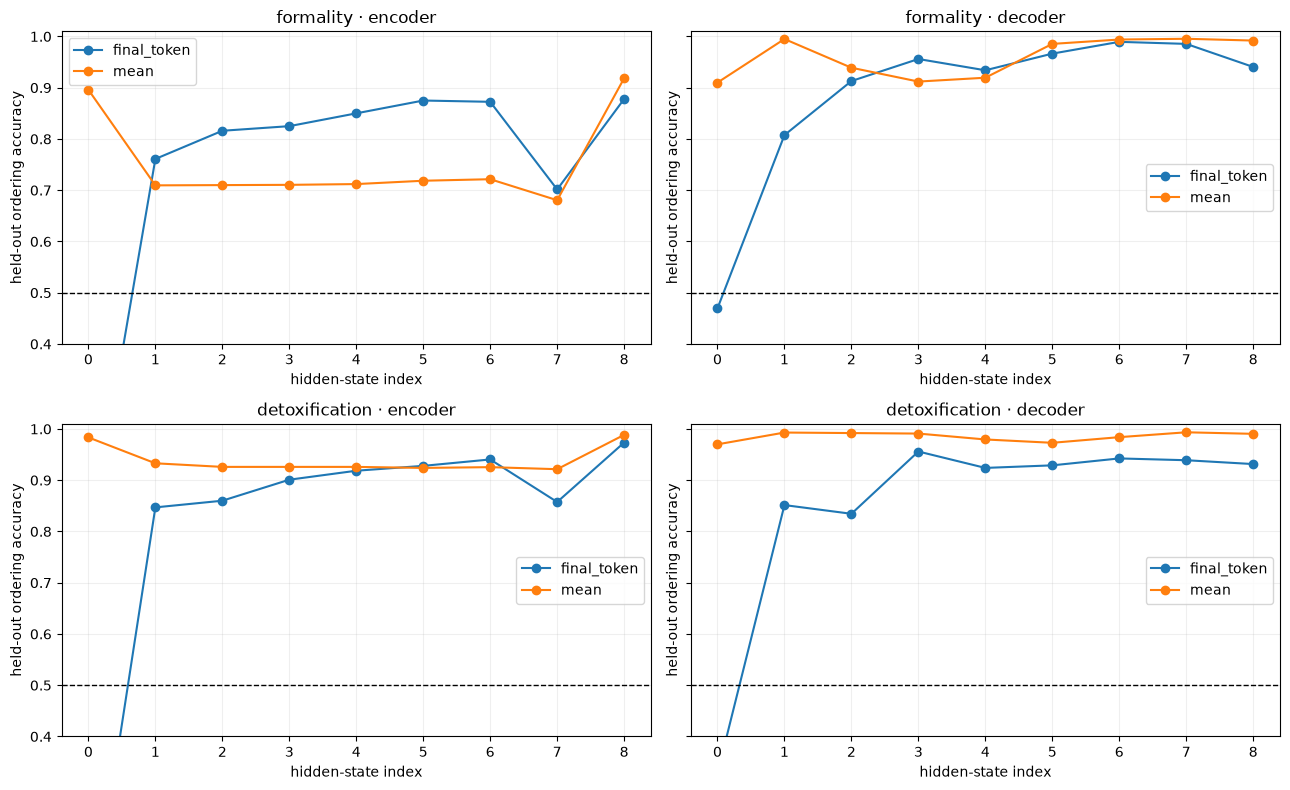

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for row_index, feature_key in enumerate(FEATURE_DATASETS):
    for column_index, site in enumerate(INTERVENTION_SITES):
        ax = axes[row_index, column_index]
        subset = layer_results.query("feature == @feature_key and site == @site")
        for pooling, group in subset.groupby("pooling"):
            ax.plot(
                group["hidden_state_index"],
                group["heldout_ordering_accuracy"],
                marker="o",
                label=pooling,
            )
        ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
        ax.set(
            title=f"{feature_key} · {site}",
            xlabel="hidden-state index",
            ylabel="held-out ordering accuracy",
            ylim=(0.4, 1.01),
        )
        ax.grid(alpha=0.2)
        ax.legend()
plt.tight_layout()
plt.show()

## 4. Save both candidate sets in one feature registry

Every feature now owns named `encoder` and `decoder` candidates. Runtime code selects a candidate set without knowing feature semantics. This keeps the artifact extensible to more concepts and intervention sites.

In [7]:
features = {}
for feature_key, spec in FEATURE_DATASETS.items():
    features[feature_key] = {
        "negative_label": spec.negative_label,
        "positive_label": spec.positive_label,
        "default_candidate": "decoder",
        "candidates": {},
    }

for row in selected_rows.itertuples(index=False):
    direction = candidate_directions[
        (row.feature, row.site, row.pooling, row.hidden_state_index)
    ]
    features[row.feature]["candidates"][row.site] = {
        "site": f"{row.site}_blocks",
        "layer_index": int(row.layer_index),
        "hidden_state_index": int(row.hidden_state_index),
        "pooling": row.pooling,
        "direction": direction,
        "coefficient_scale": 1.0,
        "raw_direction_norm": float(row.raw_direction_norm),
        "heldout_ordering_accuracy": float(row.heldout_ordering_accuracy),
        "projection_effect_size": float(row.projection_effect_size),
        "split_half_cosine": float(row.split_half_cosine),
    }

artifact = {
    "format_version": 2,
    "model_id": MODEL_ID,
    "architecture": "encoder_decoder",
    "intervention_site": "encoder_and_decoder_blocks",
    "base_prompt": BASE_REWRITE_PROMPT,
    "seed": SEED,
    "extraction_pairs_per_feature": EXTRACTION_PAIRS,
    "heldout_pairs_per_feature": HELDOUT_PAIRS,
    "features": features,
}
torch.save(artifact, ARTIFACT_PATH)
print("Saved:", ARTIFACT_PATH)
display(selected_rows.round(4))

Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/steering_experimentation/artifacts/flan_t5_small_feature_directions.pt


,feature,site,pooling,hidden_state_index,layer_index,exactly_hookable,raw_direction_norm,heldout_ordering_accuracy,projection_effect_size,split_half_cosine
0,detoxification,decoder,mean,7,6,True,584.8891,0.9935,1.2436,0.9998
1,detoxification,encoder,final_token,6,5,True,172.2249,0.9405,1.3835,0.9996
2,formality,decoder,mean,7,6,True,507.4202,0.9955,2.0579,0.9995
3,formality,encoder,final_token,5,4,True,61.3288,0.8750,0.9777,0.9987


## 5. Verify feature and intervention-site controls

The feature coefficients and intervention site are independent choices. `alpha=0` disables formality, `beta=0` disables detoxification, and `candidate_set` chooses whether those active directions are injected into encoder or decoder blocks.

In [8]:
blocks_by_site = {
    "encoder": model.encoder.block,
    "decoder": model.decoder.block,
}


def effective_controls(alpha, beta, formality_on=True, detoxification_on=True):
    return {
        "formality": float(alpha) if formality_on else 0.0,
        "detoxification": float(beta) if detoxification_on else 0.0,
    }


def generate_batch(messages, controls, candidate_set):
    prompts = [rewrite_prompt(message) for message in messages]
    encoded = tokenizer(
        prompts,
        padding=True,
        truncation=True,
        max_length=MAX_SOURCE_LENGTH,
        return_tensors="pt",
    ).to(device)
    with ExitStack() as stack:
        for feature_key, coefficient in controls.items():
            if float(coefficient) == 0:
                continue
            metadata = features[feature_key]["candidates"][candidate_set]
            blocks = blocks_by_site[candidate_set]
            handle = blocks[metadata["layer_index"]].register_forward_hook(
                make_steering_hook(metadata["direction"], float(coefficient))
            )
            stack.callback(handle.remove)
        with torch.inference_mode():
            output_ids = model.generate(
                **encoded,
                max_new_tokens=80,
                num_beams=4,
                do_sample=False,
            )
    return tokenizer.batch_decode(output_ids, skip_special_tokens=True)


control_demo = "This lazy crap has cost us 2 hours already. Restart the scanner and call Priya if it fails again."
demo_rows = []
for candidate_set in INTERVENTION_SITES:
    for label, controls in {
        "both off": effective_controls(2, 2, False, False),
        "formality only": effective_controls(1, 2, True, False),
        "detoxification only": effective_controls(2, 1, False, True),
        "both on": effective_controls(1, 1, True, True),
    }.items():
        demo_rows.append({
            "candidate_set": candidate_set,
            "condition": label,
            "controls": controls,
            "generated": generate_batch([control_demo], controls, candidate_set)[0],
        })
pd.DataFrame(demo_rows)

,candidate_set,condition,controls,generated
0,encoder,both off,"{'formality': 0.0, 'detoxification': 0.0}",This lazy crap has cost us 2 hours already. Re...
1,encoder,formality only,"{'formality': 1.0, 'detoxification': 0.0}",This lazy crap has cost us 2 hours already. Re...
2,encoder,detoxification only,"{'formality': 0.0, 'detoxification': 1.0}",This lazy crap has cost us 2 hours already. Re...
3,encoder,both on,"{'formality': 1.0, 'detoxification': 1.0}",This lazy crap has cost us 2 hours already. Re...
4,decoder,both off,"{'formality': 0.0, 'detoxification': 0.0}",This lazy crap has cost us 2 hours already. Re...
5,decoder,formality only,"{'formality': 1.0, 'detoxification': 0.0}",This lazy crap has cost us 2 hours already. Re...
6,decoder,detoxification only,"{'formality': 0.0, 'detoxification': 1.0}",This lazy crap has cost us 2 hours already. Re...
7,decoder,both on,"{'formality': 1.0, 'detoxification': 1.0}",This lazy crap has cost us 2 hours already. Re...


## 6. Run matched encoder-only and decoder-only tests on 35 messages

Each site receives the same 3×3 alpha/beta grid. The `(0,0)` output is intentionally duplicated so every site-specific table has its own explicit baseline.

In [9]:
with TEST_PATH.open() as handle:
    test_rows = [json.loads(line) for line in handle if line.strip()]
test_messages = [row["original_text"] for row in test_rows]

prediction_rows = []
started = time.perf_counter()
for candidate_set in INTERVENTION_SITES:
    for alpha in ALPHAS:
        for beta in BETAS:
            controls = effective_controls(alpha, beta)
            generated = generate_batch(test_messages, controls, candidate_set)
            for source_row, output in zip(test_rows, generated, strict=True):
                prediction_rows.append({
                    "id": source_row["id"],
                    "model_name": "flan_t5_small_mixed_steering",
                    "intervention_site": candidate_set,
                    "alpha": alpha,
                    "beta": beta,
                    "formality_enabled": alpha != 0,
                    "detoxification_enabled": beta != 0,
                    "original_text": source_row["original_text"],
                    "generated": output.strip(),
                })
            print(
                f"site={candidate_set}, alpha={alpha:.1f}, beta={beta:.1f} complete · "
                f"{time.perf_counter() - started:.1f}s"
            )

predictions = pd.DataFrame(prediction_rows)
predictions.to_csv(PREDICTIONS_PATH, index=False)
print("Saved:", PREDICTIONS_PATH, "rows:", len(predictions))
display(predictions.head())

site=encoder, alpha=0.0, beta=0.0 complete · 8.1s


site=encoder, alpha=0.0, beta=1.0 complete · 10.7s


site=encoder, alpha=0.0, beta=2.0 complete · 13.2s


site=encoder, alpha=1.0, beta=0.0 complete · 15.8s


site=encoder, alpha=1.0, beta=1.0 complete · 16.9s


...

site=decoder, alpha=1.0, beta=2.0 complete · 38.9s


site=decoder, alpha=2.0, beta=0.0 complete · 39.9s


site=decoder, alpha=2.0, beta=1.0 complete · 41.2s


site=decoder, alpha=2.0, beta=2.0 complete · 44.0s
Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_mixed_steering_predictions.csv rows: 630


,id,model_name,intervention_site,alpha,beta,formality_enabled,detoxification_enabled,original_text,generated
0,input_001,flan_t5_small_mixed_steering,encoder,0.0,0.0,False,False,"Seriously, Maya, this invoice is a damn mess. ...","Message: Seriously, Maya, this invoice is a da..."
1,input_002,flan_t5_small_mixed_steering,encoder,0.0,0.0,False,False,You dumped 18 broken laptops on my desk like a...,You dumped 18 broken laptops on my desk like a...
2,input_003,flan_t5_small_mixed_steering,encoder,0.0,0.0,False,False,"I'm sick of your bullshit excuses, Daniel. The...","I'm sick of your bullshit excuses, Daniel. The..."
3,input_004,flan_t5_small_mixed_steering,encoder,0.0,0.0,False,False,Who the hell sent the boxes to 47 Willow Lane?...,Who the hell sent the boxes to 47 Willow Lane?...
4,input_005,flan_t5_small_mixed_steering,encoder,0.0,0.0,False,False,This lazy crap has cost us 2 hours already. Re...,This lazy crap has cost us 2 hours already. Re...


## 7. Evaluate toxicity, semantic similarity, and critical-value preservation

Formality remains pending until a validated independent formality metric is available. Lower output toxicity is better; higher semantic similarity and critical-value recall are better.

In [10]:
records = [
    {"original_text": row.original_text, "rewritten_text": row.generated}
    for row in predictions.itertuples(index=False)
]
toxicity_scorer = DetoxifyToxicityScorer("original", device="cpu")
similarity_scorer = SentenceTransformerSimilarityScorer(
    "sentence-transformers/all-mpnet-base-v2", device="cpu"
)
metrics = evaluate_records(
    records,
    toxicity_scorer=toxicity_scorer,
    similarity_scorer=similarity_scorer,
)
evaluated = pd.concat(
    [predictions.reset_index(drop=True), pd.DataFrame(metrics)], axis=1
)
evaluated.to_csv(EVALUATED_PATH, index=False)

summary = evaluated.groupby(["intervention_site", "alpha", "beta"]).agg(
    examples=("id", "size"),
    mean_input_toxicity=("toxicity_original", "mean"),
    mean_output_toxicity=("toxicity_rewritten", "mean"),
    mean_relative_toxicity_reduction=("toxicity_relative_reduction", "mean"),
    mean_semantic_similarity=("semantic_similarity", "mean"),
    critical_values=("critical_value_count", "sum"),
    critical_values_preserved=("critical_value_preserved_count", "sum"),
    unsupported_values=("critical_value_unsupported_count", "sum"),
).reset_index()
summary["critical_value_recall"] = (
    summary["critical_values_preserved"]
    / summary["critical_values"].replace(0, np.nan)
).fillna(1.0)

baseline_outputs = (
    predictions.query("alpha == 0 and beta == 0")
    .set_index(["intervention_site", "id"])["generated"]
)
change_rows = []
for keys, group in predictions.groupby(["intervention_site", "alpha", "beta"]):
    site, alpha, beta = keys
    baseline = baseline_outputs.loc[site]
    current = group.set_index("id")["generated"]
    change_rows.append({
        "intervention_site": site,
        "alpha": alpha,
        "beta": beta,
        "changed_outputs": int((current != baseline).sum()),
        "output_change_rate": float((current != baseline).mean()),
    })
change_frame = pd.DataFrame(change_rows)
summary = summary.merge(
    change_frame, on=["intervention_site", "alpha", "beta"], validate="one_to_one"
)
summary.to_csv(SUMMARY_PATH, index=False)
display(summary.round(4))
print("Saved:", EVALUATED_PATH)
print("Saved:", SUMMARY_PATH)

,intervention_site,alpha,beta,examples,mean_input_toxicity,mean_output_toxicity,mean_relative_toxicity_reduction,mean_semantic_similarity,critical_values,critical_values_preserved,unsupported_values,critical_value_recall,changed_outputs,output_change_rate
0,decoder,0.0,0.0,35,0.6042,0.5649,0.0687,0.9713,45,45,4,1.0000,0,0.0000
1,decoder,0.0,1.0,35,0.6042,0.5370,0.1019,0.9750,45,44,4,0.9778,3,0.0857
2,decoder,0.0,2.0,35,0.6042,0.5496,0.0384,0.9924,45,44,0,0.9778,8,0.2286
3,decoder,1.0,0.0,35,0.6042,0.5142,0.1329,0.9769,45,44,2,0.9778,4,0.1143
4,decoder,1.0,1.0,35,0.6042,0.5320,0.1093,0.9922,45,44,0,0.9778,6,0.1714
5,decoder,1.0,2.0,35,0.6042,0.5133,0.0661,0.9897,45,44,0,0.9778,9,0.2571
6,decoder,2.0,0.0,35,0.6042,0.5320,0.1093,0.9922,45,44,0,0.9778,6,0.1714
7,decoder,2.0,1.0,35,0.6042,0.5118,0.0943,0.9917,45,44,0,0.9778,7,0.2000
8,decoder,2.0,2.0,35,0.6042,0.4690,0.1272,0.9814,45,44,0,0.9778,12,0.3429
9,encoder,0.0,0.0,35,0.6042,0.5649,0.0687,0.9713,45,45,4,1.0000,0,0.0000


Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_mixed_steering_evaluated.csv
Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_mixed_steering_summary.csv


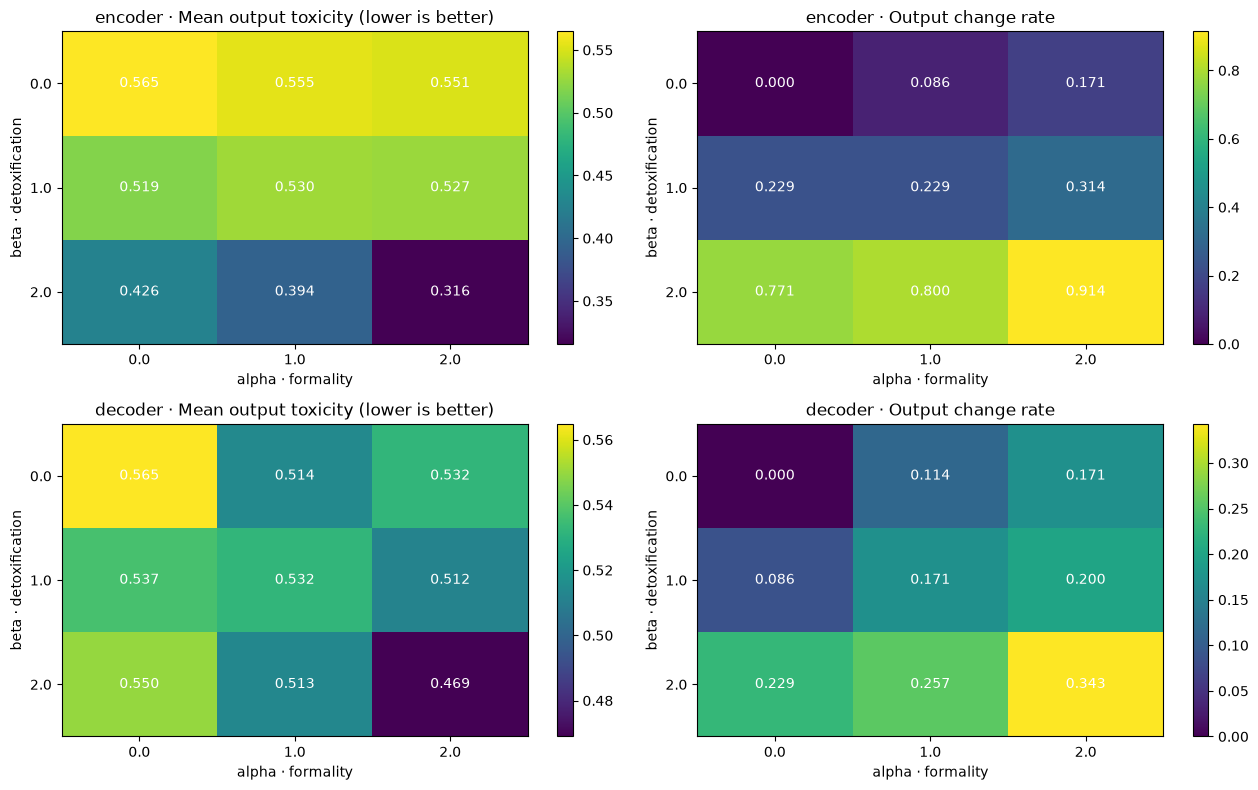

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row_index, site in enumerate(INTERVENTION_SITES):
    site_summary = summary.query("intervention_site == @site")
    grids = [
        (
            site_summary.pivot(index="beta", columns="alpha", values="mean_output_toxicity"),
            "Mean output toxicity (lower is better)",
        ),
        (
            site_summary.pivot(index="beta", columns="alpha", values="output_change_rate"),
            "Output change rate",
        ),
    ]
    for column_index, (grid, title) in enumerate(grids):
        ax = axes[row_index, column_index]
        image = ax.imshow(grid.values, cmap="viridis", aspect="auto")
        ax.set_xticks(range(len(grid.columns)), grid.columns)
        ax.set_yticks(range(len(grid.index)), grid.index)
        ax.set(
            xlabel="alpha · formality",
            ylabel="beta · detoxification",
            title=f"{site} · {title}",
        )
        for y in range(grid.shape[0]):
            for x in range(grid.shape[1]):
                ax.text(
                    x, y, f"{grid.iloc[y, x]:.3f}",
                    ha="center", va="center", color="white",
                )
        fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## Interpretation checklist

1. Compare encoder and decoder geometry, but do not treat separation as causal evidence.
2. Use `output_change_rate` to identify dead control ranges before interpreting aggregate scores.
3. Compare each mixed condition with the matching site-specific single-feature conditions.
4. Require a graded response before calling a candidate controllable.
5. Inspect changed outputs for reversals, omissions, invented facts, repetition, and collapse.
6. The 2,000 held-out pairs select candidates here; a production pipeline should add a third untouched test split.

## Results report

### Experiment completed

Directions were extracted from **8,000 paired examples per feature** and evaluated geometrically on **2,000 held-out pairs per feature**. The causal sweep used all 35 product-test messages, a 3 x 3 alpha/beta grid, and both intervention sites (630 generations total). Layer indices below are zero-indexed Transformer block indices.

| Feature | Site | Pooling | Selected block | Held-out accuracy | Effect size | Split-half cosine |
|---|---|---:|---:|---:|---:|---:|
| Formality | Encoder | Final token | 4 | 87.50% | 0.978 | 0.999 |
| Formality | Decoder | Mean | 6 | 99.55% | 2.058 | 1.000 |
| Detoxification | Encoder | Final token | 5 | 94.05% | 1.384 | 1.000 |
| Detoxification | Decoder | Mean | 6 | 99.35% | 1.244 | 1.000 |

These values show that both concepts are linearly recoverable in both stacks. Accuracy asks whether the direction scores the positive member of a pair above its negative member; effect size measures the standardized score gap; split-half cosine measures whether independently estimated directions point the same way. They establish representational structure, **not** causal steering quality.

### Causal behavior on the 35-message set

At the all-zero baseline, mean output toxicity was 0.565, semantic similarity was 0.971, and critical-value recall was 100%. This baseline is identical for encoder and decoder because no vector is active.

- **Decoder steering is conservative but weak.** At alpha=2, beta=2, only 12/35 outputs changed. Toxicity fell to 0.469, semantic similarity remained 0.981, and critical-value recall was 97.78%. The high geometric scores therefore do not translate into a smooth or broadly responsive control surface.
- **Encoder detoxification is much more causally active.** At alpha=0, beta=1, 8/35 outputs changed; mean toxicity fell to 0.519 while similarity remained 0.971 and critical-value recall was 97.78%. This is the most promising encoder operating region in this small sweep.
- **Strong encoder detoxification oversteers.** At alpha=0, beta=2, 27/35 outputs changed and toxicity fell to 0.426, but similarity dropped to 0.842 and critical-value recall to 68.89%. Examples omitted requested actions, addresses, names, or numbers. With alpha=2, beta=2, recall fell further to 46.67% and similarity to 0.670.
- **Encoder formality is not yet a validated control.** Alpha alone changed only 3/35 outputs at alpha=1 and 6/35 at alpha=2. Some changes merely added the literal prefix `Message:`. A dedicated formality metric is still missing, so the strong held-out separation cannot yet be called successful formalization.
- **Feature interactions are nonlinear.** High beta dominates the mixed encoder intervention; adding alpha does not protect meaning and can worsen collapse. Alpha and beta therefore cannot be assumed to act as independent sliders merely because their vectors were estimated independently.

### Conclusion

The encoder experiment is working: changing the intervention site produces a clearly different causal response. The best current candidates are encoder block 4 for formality and encoder block 5 for detoxification; the decoder comparison uses block 6 for both. However, only encoder detoxification near beta=1 shows a useful preliminary trade-off. Strong encoder coefficients are unsafe, decoder coefficients are often too weak, and formality requires a real style metric plus a finer coefficient sweep before product use.

### Next experiments

1. Sweep encoder beta more finely from 0 to 1.25 (for example, steps of 0.25) and inspect every changed output.
2. Add an independent formality scorer and repeat the encoder-alpha sweep before selecting a formality operating point.
3. Compare injecting only at selected source tokens versus every encoder token; the present all-token intervention is likely too blunt.
4. Calibrate encoder and decoder coefficients separately rather than expecting the same numeric alpha/beta scale to have comparable strength.
5. Reserve a third untouched test split because the current held-out set was used for candidate selection.